In [ ]:
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings('ignore')

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "params.yaml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
with (PROJECT_ROOT / "params.yaml").open(encoding="utf-8") as config_file:
    CONFIG = yaml.safe_load(config_file)

In [ ]:
DATA_PATH = PROJECT_ROOT / CONFIG["paths"]["raw_train"]

In [ ]:
df = pd.read_csv(DATA_PATH)

In [13]:
df = pd.read_csv(DATA_PATH)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Исходный размер датасета:", df.shape)

Исходный размер датасета: (150000, 11)


In [ ]:
df['MonthlyIncome_isna'] = df['MonthlyIncome'].isna().astype(int)
df['NumberOfDependents_isna'] = df['NumberOfDependents'].isna().astype(int)

df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

df['AgeGroup'] = pd.qcut(
    df['age'], q=CONFIG["features"]["age_group_count"], duplicates='drop'
)
df['MonthlyIncome'] = df.groupby('AgeGroup')['MonthlyIncome'].transform(lambda x: x.fillna(x.median()))
df.drop(columns=['AgeGroup'], inplace=True)

df['Total_PastDue_Count'] = (
    df['NumberOfTime30-59DaysPastDueNotWorse'] +
    df['NumberOfTime60-89DaysPastDueNotWorse'] +
    df['NumberOfTimes90DaysLate']
)

df['Severe_PastDue_Ratio'] = df['NumberOfTimes90DaysLate'] / (df['Total_PastDue_Count'] + 1)

df['Income_Per_Person'] = df['MonthlyIncome'] / (df['NumberOfDependents'] + 1)

df['Total_Credit_Lines'] = df['NumberOfOpenCreditLinesAndLoans'] + df['NumberRealEstateLoansOrLines']

df['Monthly_Debt_Amount'] = df['MonthlyIncome'] * df['DebtRatio']

In [15]:
print("Размер после генерации признаков:", df.shape)

Размер после генерации признаков: (150000, 18)


In [ ]:
training_params = CONFIG["training"]
X = df.drop(columns=['SeriousDlqin2yrs'])
y = df['SeriousDlqin2yrs']

skf = StratifiedKFold(
    n_splits=training_params["cv_splits"],
    shuffle=True,
    random_state=training_params["random_state"],
)
oof_preds = np.zeros(len(df))
models = []

In [ ]:
print("Запуск валидации Stratified K-Fold")
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(**CONFIG["lightgbm"])
    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[
            lgb.early_stopping(
                training_params["early_stopping_rounds"], verbose=False
            )
        ],
    )

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds
    fold_auc = roc_auc_score(y_val, val_preds)
    models.append(model)

    print(f"Fold {fold + 1} | ROC-AUC: {fold_auc:.5f}")

overall_auc = roc_auc_score(y, oof_preds)
print("Итоговый Baseline OOF ROC-AUC:", overall_auc)

Запуск валидации 5-Fold Stratified K-Fold
Fold 1 | ROC-AUC: 0.86419
Fold 2 | ROC-AUC: 0.86555
Fold 3 | ROC-AUC: 0.86980
Fold 4 | ROC-AUC: 0.86014
Fold 5 | ROC-AUC: 0.86993
Итоговый Baseline OOF ROC-AUC: 0.8657790974409425


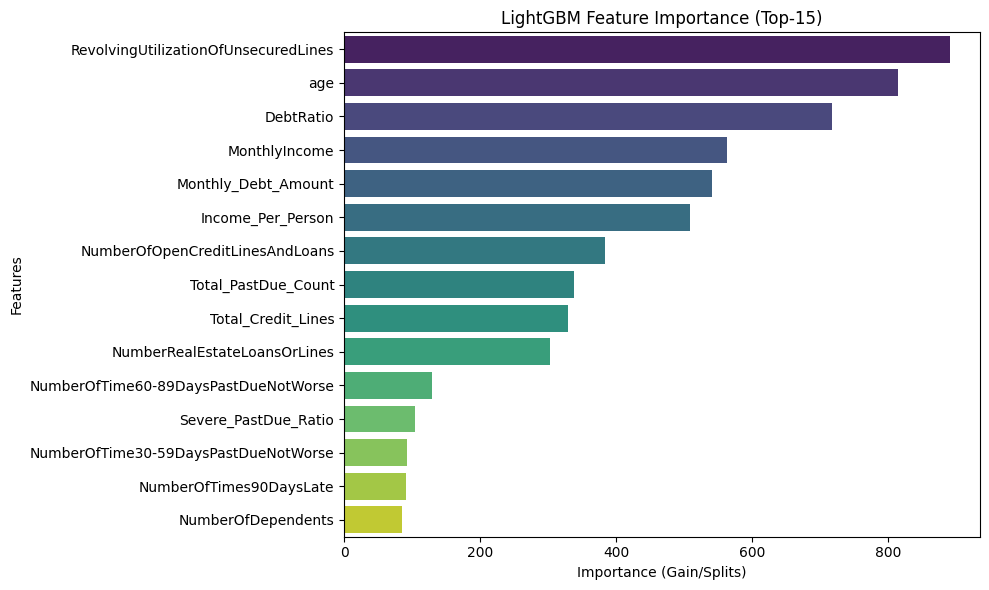

In [20]:
feature_importances = pd.DataFrame()
feature_importances['feature'] = X.columns

importance_values = np.zeros(len(X.columns))
for model in models:
    importance_values += model.feature_importances_ / len(models)

feature_importances['importance'] = importance_values
feature_importances = feature_importances.sort_values(by='importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importances.head(15), palette='viridis')
plt.title('LightGBM Feature Importance (Top-15)')
plt.xlabel('Importance (Gain/Splits)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()